# Laboratorium 6 — Warstwa łącząca (pooling) i pełna CNN

**Cel:** zrozumieć pooling (max, average, global), porównać go ze splotem z krokiem i złożyć kompletną CNN. Na koniec porównamy warianty poolingu pod kątem accuracy i liczby parametrów.

*Prowadzący: dr Tomasz Cieplak / mgr inż. Patryk Marek, Rok akademicki: 2026/27*

## 0. Instalacja zależności

In [1]:
!pip install torch torchvision matplotlib

## Import bibliotek i wybór urządzenia

In [2]:
import time, urllib.request
import numpy as np
import torch
import torch.nn as nn
from torch.utils.data import DataLoader
import torchvision
from torchvision import transforms
import matplotlib.pyplot as plt

torch.manual_seed(0)
device = "cuda" if torch.cuda.is_available() else "cpu"
print("PyTorch:", torch.__version__, "| urządzenie:", device)

PyTorch: 2.11.0+cu128 | urządzenie: cuda


## 1. Mechanika poolingu

Pooling agreguje wartości w oknie (np. 2×2) do jednej liczby. Zobaczmy to na małej macierzy — max bierze maksimum, average średnią.

In [3]:
x = torch.tensor([[1., 2., 5., 6.],
                  [3., 4., 7., 8.],
                  [9., 1., 2., 0.],
                  [8., 6., 4., 3.]]).view(1,1,4,4)
print("wejście 4x4:\n", x[0,0].numpy())
print("\nMax pooling 2x2:\n", nn.MaxPool2d(2)(x)[0,0].numpy())
print("\nAverage pooling 2x2:\n", nn.AvgPool2d(2)(x)[0,0].numpy())

wejście 4x4:
 [[1. 2. 5. 6.]
 [3. 4. 7. 8.]
 [9. 1. 2. 0.]
 [8. 6. 4. 3.]]

Max pooling 2x2:
 [[4. 8.]
 [9. 4.]]

Average pooling 2x2:
 [[2.5  6.5 ]
 [6.   2.25]]


## 2. Pooling na obrazie

Ten sam obraz po max i average poolingu 2×2 — wymiar spada o połowę. Max wyostrza, average wygładza.

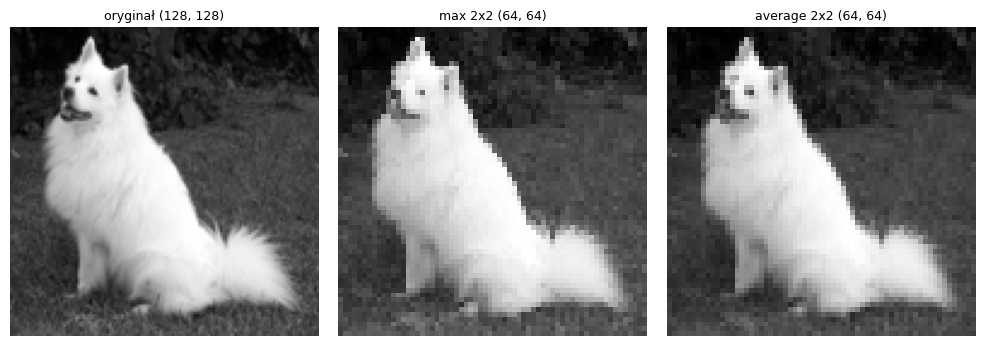

In [4]:
try:
    urllib.request.urlretrieve("https://github.com/pytorch/hub/raw/master/images/dog.jpg", "img.jpg")
    pil = __import__('PIL.Image', fromlist=['Image']).open("img.jpg").convert("L").resize((128,128))
    img = torch.from_numpy(np.array(pil)).float().view(1,1,128,128)/255.0
except Exception as e:
    print("Brak sieci, obraz syntetyczny:", e)
    yy, xx = np.mgrid[0:128,0:128]
    img = torch.from_numpy(((np.sin(xx/6.0)*0.5+0.5))).float().view(1,1,128,128)

mx = nn.MaxPool2d(2)(img); av = nn.AvgPool2d(2)(img)
fig, axes = plt.subplots(1,3, figsize=(10,3.4))
for ax,(t,name) in zip(axes, [(img,'oryginał'),(mx,'max 2x2'),(av,'average 2x2')]):
    ax.imshow(t[0,0], cmap='gray'); ax.set_title(f"{name} {tuple(t.shape[-2:])}", fontsize=9); ax.axis('off')
plt.tight_layout(); plt.show()

## 3. Global average pooling (GAP)

GAP uśrednia każdą mapę cech do jednej liczby: `[C, H, W] → [C, 1, 1]`. Zastępuje duże warstwy gęste na końcu sieci.

In [5]:
fmap = torch.randn(1, 64, 7, 7)  # mapa cech: 64 kanały 7x7
gap = nn.AdaptiveAvgPool2d(1)(fmap)
print("przed GAP:", tuple(fmap.shape), "-> po GAP:", tuple(gap.shape))
print("po spłaszczeniu:", tuple(gap.flatten(1).shape))  # [1, 64]

przed GAP: (1, 64, 7, 7) -> po GAP: (1, 64, 1, 1)
po spłaszczeniu: (1, 64)


## 4. Pełna CNN z konfigurowalnym poolingiem

Blok: splot → BN → ReLU → **redukcja**. Redukcję realizujemy jako max pooling, average pooling albo **splot z krokiem** (uczony). Na końcu GAP + warstwa gęsta.

In [6]:
class CNN(nn.Module):
    def __init__(self, n_classes=10, pool="max"):
        super().__init__()
        def block(cin, cout):
            layers = [nn.Conv2d(cin, cout, 3, padding=1), nn.BatchNorm2d(cout), nn.ReLU()]
            if pool == "max":
                layers.append(nn.MaxPool2d(2))
            elif pool == "avg":
                layers.append(nn.AvgPool2d(2))
            elif pool == "stride":
                layers += [nn.Conv2d(cout, cout, 3, stride=2, padding=1), nn.BatchNorm2d(cout), nn.ReLU()]
            return nn.Sequential(*layers)
        self.features = nn.Sequential(block(1, 32), block(32, 64))  # 28 -> 14 -> 7
        self.head = nn.Sequential(nn.AdaptiveAvgPool2d(1), nn.Flatten(), nn.Linear(64, n_classes))
    def forward(self, x):
        return self.head(self.features(x))

def count(m): return sum(p.numel() for p in m.parameters())
for p in ["max", "avg", "stride"]:
    m = CNN(pool=p)
    out = m(torch.randn(2,1,28,28))
    print(f"pool={p:6} | parametry {count(m):>7,} | wyjście {tuple(out.shape)}")

pool=max    | parametry  19,658 | wyjście (2, 10)
pool=avg    | parametry  19,658 | wyjście (2, 10)
pool=stride | parametry  66,026 | wyjście (2, 10)


## 5. Eksperyment: warianty poolingu na FashionMNIST

Trenujemy trzy warianty tyle samo epok i porównujemy accuracy oraz liczbę parametrów. (FashionMNIST — szybki zbiór; wnioski przenoszą się na inne zbiory.)

In [7]:
tf = transforms.Compose([transforms.ToTensor(), transforms.Normalize((0.2860,), (0.3530,))])
train_ds = torchvision.datasets.FashionMNIST("./data", train=True,  download=True, transform=tf)
test_ds  = torchvision.datasets.FashionMNIST("./data", train=False, download=True, transform=tf)
train_dl = DataLoader(train_ds, batch_size=128, shuffle=True)
test_dl  = DataLoader(test_ds,  batch_size=256, shuffle=False)

def evaluate(model, dl):
    model.eval(); correct = total = 0
    with torch.no_grad():
        for xb, yb in dl:
            xb, yb = xb.to(device), yb.to(device)
            correct += (model(xb).argmax(1) == yb).sum().item(); total += yb.numel()
    return correct/total

def train(model, epochs=6):
    model = model.to(device); crit = nn.CrossEntropyLoss()
    opt = torch.optim.Adam(model.parameters(), lr=1e-3); accs = []
    for e in range(epochs):
        model.train()
        for xb, yb in train_dl:
            xb, yb = xb.to(device), yb.to(device)
            opt.zero_grad(); crit(model(xb), yb).backward(); opt.step()
        accs.append(evaluate(model, test_dl))
    return accs

results = {}
for p in ["max", "avg", "stride"]:
    m = CNN(pool=p)
    accs = train(m, epochs=6)
    results[p] = (accs, count(m))
    print(f"pool={p:6} | best acc {max(accs)*100:.2f}% | parametry {count(m):,}")

100%|██████████| 26.4M/26.4M [00:02<00:00, 11.6MB/s]
100%|██████████| 29.5k/29.5k [00:00<00:00, 170kB/s]
100%|██████████| 4.42M/4.42M [00:01<00:00, 3.14MB/s]
100%|██████████| 5.15k/5.15k [00:00<00:00, 22.2MB/s]


pool=max    | best acc 81.83% | parametry 19,658
pool=avg    | best acc 80.05% | parametry 19,658
pool=stride | best acc 89.86% | parametry 66,026


## Porównanie — krzywe i tabela

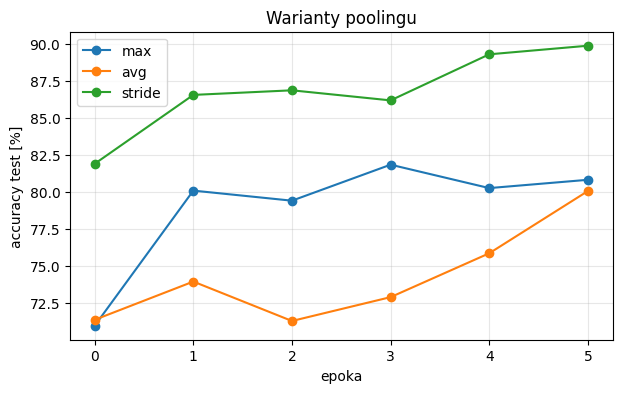

pool    |  parametry |  best acc
----------------------------------
max     |     19,658 |    81.83%
avg     |     19,658 |    80.05%
stride  |     66,026 |    89.86%


In [8]:
plt.figure(figsize=(7,4))
for p,(accs,_) in results.items():
    plt.plot([a*100 for a in accs], "o-", label=p)
plt.xlabel("epoka"); plt.ylabel("accuracy test [%]"); plt.legend(); plt.title("Warianty poolingu")
plt.grid(alpha=0.3); plt.show()

print(f"{'pool':7} | {'parametry':>10} | {'best acc':>9}")
print('-'*34)
for p,(accs,n) in results.items():
    print(f"{p:7} | {n:>10,} | {max(accs)*100:>8.2f}%")

## 6. Podsumowanie

- Pooling redukuje wymiar przestrzenny, zwiększa pole recepcyjne i daje niezmienniczość na drobne przesunięcia; nie ma uczonych parametrów.
- Max podkreśla najsilniejsze cechy, average uśrednia; GAP zastępuje duże warstwy gęste.
- Splot z krokiem to uczona alternatywa dla poolingu (więcej parametrów).
- Pełna CNN = bloki splot–ReLU–redukcja + GAP/FC na końcu.

**Zadanie na sprawozdanie:** zobacz `zadanie.md`.

---
*Prowadzący: dr Tomasz Cieplak / mgr inż. Patryk Marek, Rok akademicki: 2026/27*